# Quadratic coefficients

$$dX_t = (0.7X_t + 0.3X_t^2)\,dt + (0.5X_t + 0.1X_t^2)\,dB_t^P.$$

Use the simulation, diffusion settings, and Method 2 noise recovery from
`Stochastic_SINDy_Quadratic.ipynb`. Compare both drift methods and ODE2 with
$\mu(X_t)$, then fit SSISDE. `S` denotes the sampled path $X$.
Run all cells with the project Python environment.


In [1]:
from pathlib import Path
import os
import sys

roots = [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]
PROJECT_ROOT = next((p for p in roots if (p / 'models/stochastic_sindy.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the SSISDE checkout first. On Colab, download it with the Black-Scholes setup cell.')
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / 'experiments/quadratic')
RESULTS = PROJECT_ROOT / 'outputs/quadratic'
RESULTS.mkdir(parents=True, exist_ok=True)


In [2]:
%pip install -q -r ../../requirements.txt



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
import pysindy as ps
from sklearn import linear_model
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit
from tqdm import tqdm
import iisignature



/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


## Simulate $X$

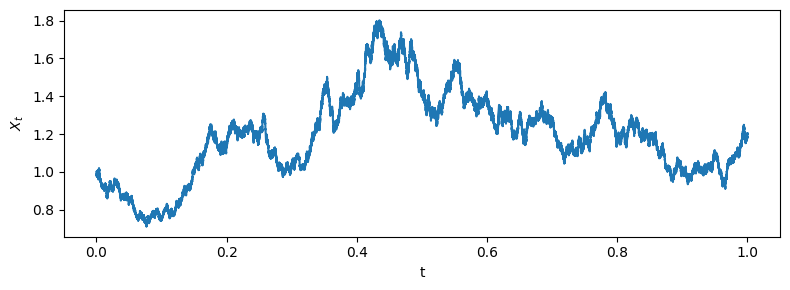

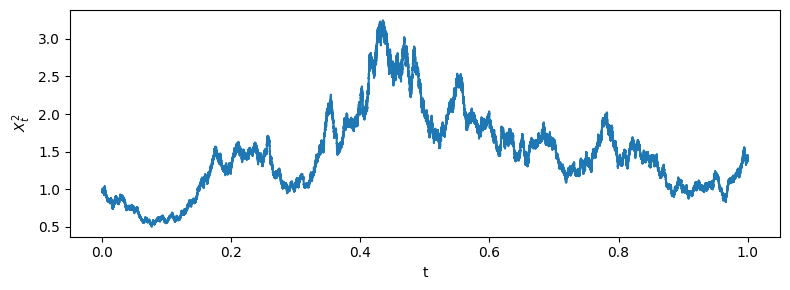

In [4]:
from data_generation.quadratic import generate_data
N, T, S0, seed = 100000, 1, 1.0, 2
r = 0.5
t, dt, S_, W_, mu_exact_, sigma_exact_ = generate_data(N, T, S0, seed)

plt.figure(figsize=(8, 3))
plt.plot(t, S_)
plt.xlabel('t')
plt.ylabel(r'$X_t$')
plt.tight_layout()
plt.savefig('path.png', dpi=200)
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(t, S_**2)
plt.xlabel('t')
plt.ylabel(r'$X_t^2$')
plt.tight_layout()
plt.savefig('squared_path.png', dpi=200)
plt.show()


## Estimate $\sigma$ from quadratic variation

Use the supplied SR3 settings: `threshold=0.04`, `nu=0.05`,
`max_iter=500`, and `tol=1e-14`. The degree-4 library has no constant term.


In [5]:
from models.quadratic_variation import estimate_quadratic_variation
QV, dQV, diff_method = estimate_quadratic_variation(S_, t)


  0%|          | 0/100000 [00:00<?, ?it/s]

 13%|█▎        | 13298/100000 [00:00<00:00, 132958.89it/s]

 27%|██▋       | 26594/100000 [00:00<00:00, 85021.84it/s] 

 36%|███▌      | 36063/100000 [00:00<00:00, 65836.72it/s]

 43%|████▎     | 43391/100000 [00:00<00:01, 56126.56it/s]

...

 92%|█████████▏| 92194/100000 [00:02<00:00, 21913.91it/s]

 94%|█████████▍| 94375/100000 [00:02<00:00, 21397.50it/s]

 97%|█████████▋| 96507/100000 [00:02<00:00, 20871.00it/s]

 99%|█████████▊| 98588/100000 [00:02<00:00, 20394.59it/s]

100%|██████████| 100000/100000 [00:03<00:00, 33148.27it/s]

In [6]:
from models.diffusion_quadratic import fit_quadratic_diffusion
model = fit_quadratic_diffusion(S_, t, dQV)
print(model.equations())

sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_equation = model.equations(precision=6)[0]
sigma_settings = dict(threshold=0.04, nu=0.05, max_iter=500, tol=1e-14,
                      degree=4, include_bias=False)
print('sigma^2(X) =', sigma_equation)


['0.216 x0 + -0.356 x0^2 + 0.652 x0^3 + -0.153 x0^4']
sigma^2(X) = 0.216292 x0 + -0.355605 x0^2 + 0.652193 x0^3 + -0.152685 x0^4


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/optimizers/sr3.py:390: ConvergenceWarning: SR3._reduce did not converge after 500 iterations.
  warnings.warn(


Diffusion RMSE: 0.00383067


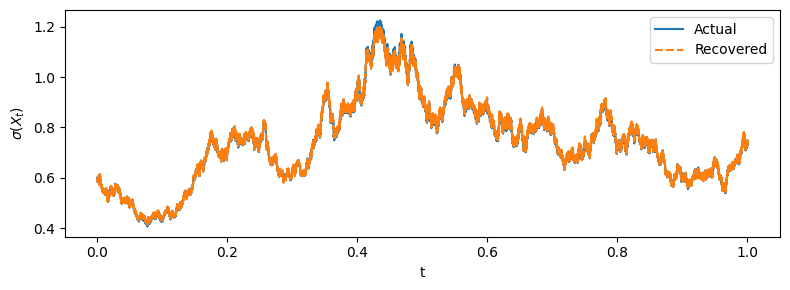

In [7]:
sigma_rmse = float(np.sqrt(np.mean((sigma_pred_.ravel() - sigma_exact_)**2)))
print(f'Diffusion RMSE: {sigma_rmse:.6g}')

plt.figure(figsize=(8, 3))
plt.plot(t, sigma_exact_, label='Actual')
plt.plot(t, sigma_pred_, '--', label='Recovered')
plt.xlabel('t')
plt.ylabel(r'$\sigma(X_t)$')
plt.legend()
plt.tight_layout()
plt.savefig('diffusion.png', dpi=200)
plt.show()


## Recover $B^Q$ and estimate $\psi_{21}$

In [8]:
from models.diffusion_derivatives import diffusion_derivatives
sigma_prime_, sigma_2prime_, sigma_3prime_ = diffusion_derivatives(sigma_pred_, S_, diff_method)
from models.q_brownian_motion import recover_q_noise
BQ_ = recover_q_noise(S_, sigma_pred_)

keep_cols = [0, 1, 3, 4, 5, 13]
from models.signature_regression import fit_signature
M = 100
K = int(N/M)
l21 = fit_signature(S_, BQ_, t, keep_cols, M)
from data_generation.coarse_graining import coarse_grain
sigma_pred, mu_exact, S, BQ, W, sigma_exact = coarse_grain(
    S_, BQ_, W_, mu_exact_, sigma_exact_, sigma_pred_, M, K,
)
from models.coarse_diffusion_derivatives import coarse_diffusion_derivatives
sigma_prime, sigma_2prime, sigma_3prime = coarse_diffusion_derivatives(sigma_pred, S, diff_method)


  0%|          | 0/1000 [00:00<?, ?it/s]

 20%|█▉        | 195/1000 [00:00<00:00, 1944.19it/s]

 39%|███▉      | 391/1000 [00:00<00:00, 1948.14it/s]

 59%|█████▊    | 587/1000 [00:00<00:00, 1949.80it/s]

 78%|███████▊  | 782/1000 [00:00<00:00, 1941.63it/s]

 98%|█████████▊| 977/1000 [00:00<00:00, 1944.01it/s]

100%|██████████| 1000/1000 [00:00<00:00, 1941.50it/s]

## Recover $\mu$

Method 1 estimates $\psi_{21}$ by signature regression. Method 2 uses the
diffusion estimate. ODE2 uses the initial slope $\mu'(X_0)=0.7+0.6X_0=1.3$.
All three start from the supplied initial drift $\mu(X_0)$.


In [9]:
from models.drift_coefficients import drift_coefficients
mu_0, a, b, b_ = drift_coefficients(mu_exact, sigma_pred, sigma_prime, sigma_2prime, l21)
from models.drift_recovery import recover_drift
mu_pred1, mu_pred2 = recover_drift(S, a, b, b_, mu_0)

lambda_0 = 0.7 + 0.6*S0
from models.drift_recovery_from_ODE2 import recover_drift_ode2
mu_pred11, lamda_pred = recover_drift_ode2(S, sigma_pred, sigma_prime, sigma_2prime, mu_0, lambda_0)


Method 1: drift RMSE = 0.036387
Method 2: drift RMSE = 0.0893962
ODE2: drift RMSE = 0.155729


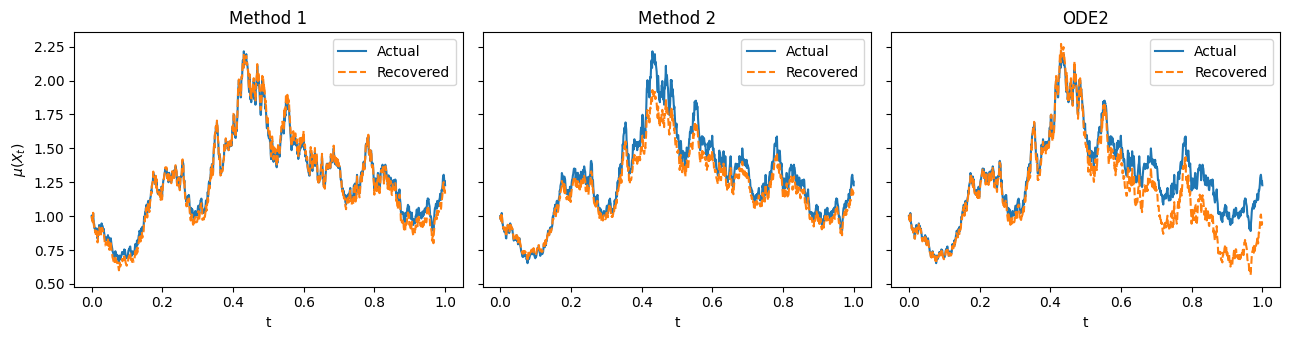

In [10]:
t_ = np.linspace(0, T, K)
drift_estimates = {'Method 1': mu_pred1, 'Method 2': mu_pred2, 'ODE2': mu_pred11}
drift_rmse = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, estimate) in zip(axes, drift_estimates.items()):
    drift_rmse[name] = float(np.sqrt(np.mean((estimate - mu_exact)**2)))
    ax.plot(t_, mu_exact, label='Actual')
    ax.plot(t_, estimate, '--', label='Recovered')
    ax.set_title(name)
    ax.set_xlabel('t')
    ax.legend()
    print(f"{name}: drift RMSE = {drift_rmse[name]:.6g}")
axes[0].set_ylabel(r'$\mu(X_t)$')
fig.tight_layout()
fig.savefig('drift_comparison.png', dpi=200)
plt.show()


## Recover $B^P$ using Method 2

As in the supplied notebook, use `mu_pred2` to recover the physical Brownian motion.


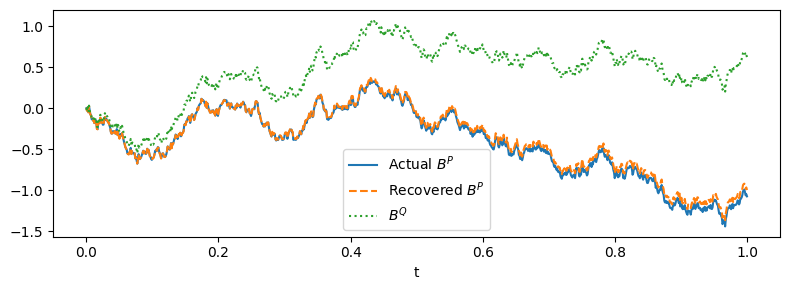

In [11]:
from models.p_brownian_motion_method2 import recover_p_noise_method2
model = "Psi_true_Quad"
BP, dt, t = recover_p_noise_method2(BQ, mu_pred2, sigma_pred, T)

plt.figure(figsize=(8, 3))
plt.plot(t, W, label=r'Actual $B^P$')
plt.plot(t, BP, '--', label=r'Recovered $B^P$')
plt.plot(t, BQ, ':', label=r'$B^Q$')
plt.xlabel('t')
plt.legend()
plt.tight_layout()
plt.savefig('noise.png', dpi=200)
plt.show()


## SSISDE

MSE: 1.454e-07
μ(X) = 1.02213*X
σ(X) = -0.0199718 + 0.540087*X + 0.0823874*X^2
[CV best] alpha=0.000873, l1_ratio (rho)=0.40


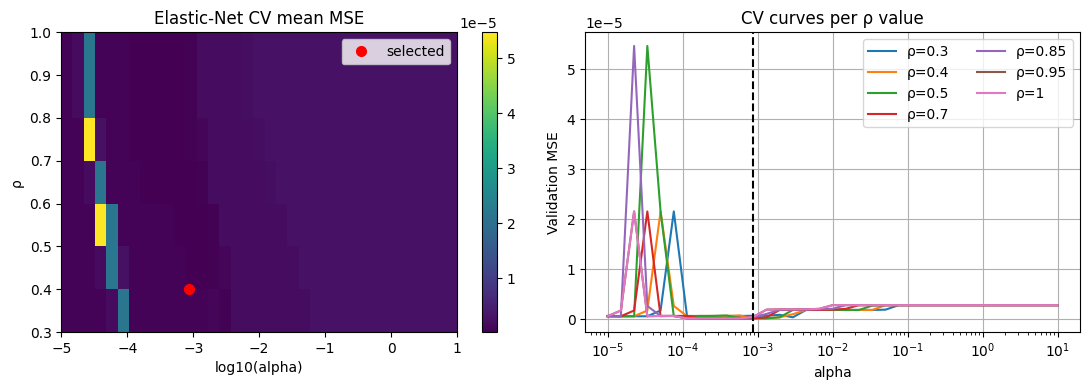

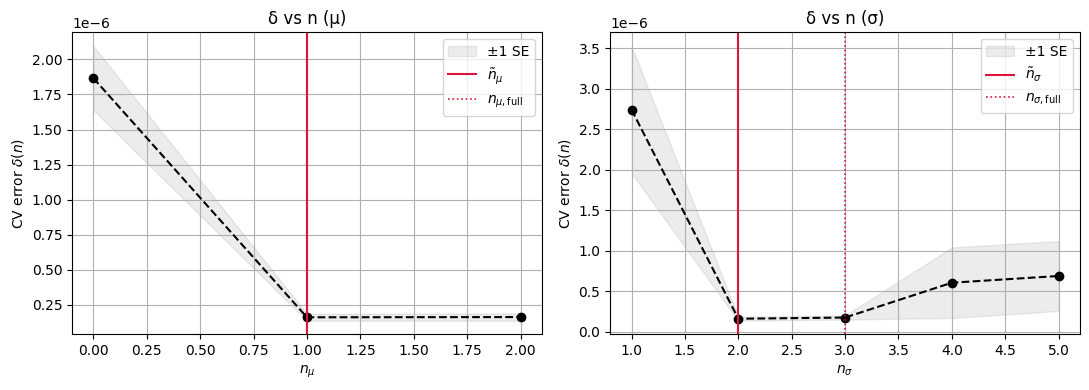

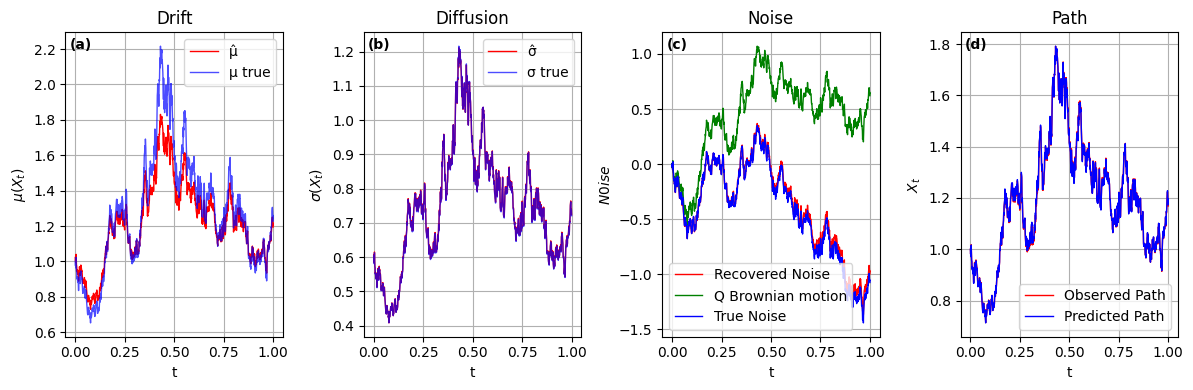

In [12]:
from models.stochastic_sindy import StochSINDy

identifier = StochSINDy(
    mu_deg=5, si_deg=5, pen='elasticnet', use_cv=True, k=7,
    alphas=np.geomspace(1e-5, 1e1, 35),
    rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0], use_1se=True,
)
identifier.fit(S, BP, dt)
identifier.show()
identifier.plot_cv(output_prefix=model)
identifier.plot_size(count_bias=True, output_prefix=model)
identifier.plot_results(S, BP, BQ, W, mu_true=mu_exact, si_true=sigma_exact, output_prefix=model)


In [13]:
results = {
    'experiment': 'quadratic',
    'seed': seed,
    'noise_recovery_method': 'Method 2',
    'ode2_initial_slope': lambda_0,
    'samples': N,
    'state_range': [float(S_.min()), float(S_.max())],
    'sigma_settings': sigma_settings,
    'sigma_squared_equation': sigma_equation,
    'sigma_rmse': sigma_rmse,
    'drift_rmse': drift_rmse,
    'noise_rmse': float(np.sqrt(np.mean((BP - W)**2))),
    'ssisde_increment_mse': identifier.mse,
    'ssisde_drift_rmse': float(np.sqrt(np.mean((identifier.mu(S) - mu_exact)**2))),
    'ssisde_diffusion_rmse': float(np.sqrt(np.mean((identifier.si(S) - sigma_exact)**2))),
    'ssisde_mu': identifier._fmt_poly(identifier.mu_c),
    'ssisde_sigma': identifier._fmt_poly(identifier.si_c),
}
(RESULTS / 'results.json').write_text(json.dumps(results, indent=2))
print(f"SSISDE increment MSE: {identifier.mse:.6g}")


SSISDE increment MSE: 1.45359e-07


## Result

The supplied settings reproduce the reported SSISDE fit: $\hat\mu(X)=1.02213X$ and $\hat\sigma(X)=-0.0199718+0.540087X+0.0823874X^2$. The increment MSE is approximately $1.454\times10^{-7}$.

The diffusion fit reaches its 500-iteration limit; its settings are retained from the supplied notebook. ODE2 is shown as an additional comparison and has a larger drift error in this case. Noise recovery and SSISDE use Method 2, as in the source.
